In [ ]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
import optuna
import sys
from pathlib import Path
import torch # Torch needs to be installed manually if you want cuda. See installation command on pytorch website
import warnings

# Notebook lives in notebooks/xxbonkxx/models/quantiles, so the repo root is four levels up
# and the shared feature module is in the parent models directory.
DIR_ROOT = Path.cwd().parent.parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))
sys.path.insert(0, str(Path.cwd().parent))

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2


In [ ]:
SEED = 987
TRACK = "off_market"                     # "off_market" or "list_aware"
VAL_START = pd.Timestamp("2025-12-01")    # sales on or after this date are validation
N_TRIALS = 10                             # optuna trials
N_ESTIMATORS = 2000                      # max boosting rounds per trial
EARLY_STOPPING_ROUNDS = 100
ES_FRACTION = 0.1                         # latest share of each fold's training rows used for early stopping
K_FOLDS = 5                              # time series cross validation folds
QUANTILE_ALPHA = 0.5                     # pinball level; 0.5 predicts the quantile itself
DEBUG = True                             # print the score for every fold


In [3]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")


In [4]:
from xxbonkxx_features import (
    off_market_features,
    list_aware_features,
    log_sold_price_quantile,
)

make_features = off_market_features if TRACK == "off_market" else list_aware_features

train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

# The model predicts where a sale sits in the fitting sales' log-price distribution.
# Quantiles for a fold are built inside cross_val, from that fold's fitting sales only.
y_train = log_sold_price_quantile(train["sold_price"], train["sold_price"])

print(f"Features: {make_features(train.iloc[:1]).columns.tolist()}")
print(f"train: {len(train):,} sales up to {VAL_START.date()}")
print(f"val:   {len(val):,} sales from {VAL_START.date()}")
print(f"train quantiles: min {y_train.min():.3f}  median {np.median(y_train):.3f}  max {y_train.max():.3f}")


Features: ['square_feet', 'bedrooms', 'washrooms', 'parking', 'lot_front', 'lot_depth', 'latitude', 'longitude', 'community', 'house_type', 'house_style', 'is_apartment', 'total_rooms', 'bedroom_density', 'bathroom_density', 'bedroom_to_bathroom_ratio', 'month', 'year', 'day', 'month_sin', 'month_cos', 'lag_annual', 'lag_semi_annual']
train: 139,931 sales up to 2025-12-01
val:   10,069 sales from 2025-12-01
train quantiles: min 0.000  median 0.500  max 1.000


In [5]:
from sklearn.metrics import mean_pinball_loss

def pinball(y, pred):
    return mean_pinball_loss(y, pred, alpha=QUANTILE_ALPHA)

loss = pinball


In [6]:
from sklearn.model_selection import TimeSeriesSplit


def align_categories(X_tr, X_va):
    """Give X_va's categorical columns the categories of X_tr. Unseen values become missing."""
    X_va = X_va.copy()
    for col in X_tr.select_dtypes("category"):
        X_va[col] = X_va[col].cat.set_categories(X_tr[col].cat.categories)
    return X_va


def cross_val(homes, params, K=5, debug=False, validation_loss=pinball):
    """Walk-forward K-fold: each fold trains on every row before its validation block.
    homes must be sorted by time (listings is sorted by date_sold).
    The target is the quantile of log sold price within the fold's fitting sales.
    Early-stopping and validation rows are scored against that same fitting distribution,
    never against later sales. The model is trained and scored with pinball loss on
    that quantile, and the predictions stay quantiles.
    Features are built inside the fold. Price lags for the validation rows use only
    that fold's training sales. Early stopping uses the latest ES_FRACTION of each
    fold's training rows, never the validation block.
    Returns (mean validation loss, mean boosting rounds used) over the folds."""
    scores = []
    rounds = []
    for fold, (train_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=K).split(homes), start=1):
        n_fit = int(len(train_idx) * (1 - ES_FRACTION))
        fit_idx, es_idx = train_idx[:n_fit], train_idx[n_fit:]
        train_homes = homes.iloc[train_idx]
        fit_prices = homes.iloc[fit_idx]["sold_price"]
        X_tr = make_features(train_homes)
        X_va = align_categories(
            X_tr, make_features(homes.iloc[val_idx], history=train_homes)
        )
        X_fit, X_es = X_tr.iloc[:n_fit], X_tr.iloc[n_fit:]
        y_fit = log_sold_price_quantile(fit_prices, fit_prices)
        y_es = log_sold_price_quantile(homes.iloc[es_idx]["sold_price"], fit_prices)
        y_va = log_sold_price_quantile(homes.iloc[val_idx]["sold_price"], fit_prices)

        model = XGBRegressor(**params, objective="reg:quantileerror", quantile_alpha=QUANTILE_ALPHA,
                             device=DEVICE, n_estimators=N_ESTIMATORS,
                             early_stopping_rounds=EARLY_STOPPING_ROUNDS, random_state=SEED)
        model.fit(X_fit, y_fit, eval_set=[(X_es, y_es)], verbose=False)
        rounds.append(model.best_iteration + 1)
        pred_q = np.clip(model.predict(X_va), 0, 1)
        scores.append(validation_loss(y_va, pred_q))

        if debug:
            print(f"fold {fold}: train {len(fit_idx):,}  early stop {len(es_idx):,}  val {len(val_idx):,}  "
                  f"rounds {rounds[-1]}  pinball {scores[-1]:.4f}", flush=True)

    print(f"mean pinball {np.mean(scores):.4f}", flush=True)
    return np.mean(scores), int(np.mean(rounds))


In [7]:
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
        "max_depth": trial.suggest_int("max_depth", 3, 13),
        "subsample": trial.suggest_float("subsample", 0.1, 1.0, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0, step=0.1),
        "max_bin": trial.suggest_int("max_bin", 256, 2048),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 0.1, step=0.01),
        "lambda": trial.suggest_float("lambda", 1e-3, 10.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-3, 10.0, log=True),
        "max_delta_step": trial.suggest_int("max_delta_step", 1, 10),
        "enable_categorical": True,
    }
    score, n_rounds = cross_val(train, params, K=K_FOLDS, debug=DEBUG, validation_loss=loss)
    trial.set_user_attr("n_rounds", n_rounds)
    return score


In [8]:
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name="log_sold_price_quantile")
study.optimize(objective, n_trials=N_TRIALS)

print("best CV pinball:", round(study.best_value, 4))
print("best params:", study.best_params)
print("boosting rounds:", study.best_trial.user_attrs["n_rounds"])


[I 2026-10-20 19:53:14,908] A new study created in memory with name: log_sold_price_quantile


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 519  pinball 0.0426
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 384  pinball 0.0443
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 983  pinball 0.0432
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 516  pinball 0.0404
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 861  pinball 0.0437
mean pinball 0.0428


[I 2026-10-20 19:53:25,549] Trial 0 finished with value: 0.04283948005003384 and parameters: {'learning_rate': 0.05, 'max_depth': 7, 'subsample': 0.9, 'colsample_bytree': 0.5, 'max_bin': 1778, 'min_child_weight': 10, 'gamma': 0.1, 'lambda': 7.103714746188992, 'alpha': 0.0013187949354214168, 'max_delta_step': 1}. Best is trial 0 with value: 0.04283948005003384.


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 381  pinball 0.0434
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 471  pinball 0.0451
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 645  pinball 0.0432
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 699  pinball 0.0415
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 602  pinball 0.0448
mean pinball 0.0436


[I 2026-10-20 19:53:32,166] Trial 1 finished with value: 0.043595691721649836 and parameters: {'learning_rate': 0.09, 'max_depth': 3, 'subsample': 0.8, 'colsample_bytree': 0.8, 'max_bin': 808, 'min_child_weight': 3, 'gamma': 0.08, 'lambda': 4.791227993546376, 'alpha': 0.0058203973119644765, 'max_delta_step': 9}. Best is trial 0 with value: 0.04283948005003384.


...

fold 1: train 20,993  early stop 2,333  val 23,321  rounds 1749  pinball 0.0423
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 1392  pinball 0.0422
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 1994  pinball 0.0414
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 1611  pinball 0.0391
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 1994  pinball 0.0412
mean pinball 0.0412


[I 2026-10-20 19:56:04,619] Trial 8 finished with value: 0.04124369611929728 and parameters: {'learning_rate': 0.02, 'max_depth': 7, 'subsample': 0.4, 'colsample_bytree': 0.8, 'max_bin': 325, 'min_child_weight': 1, 'gamma': 0.01, 'lambda': 9.311413198108736, 'alpha': 0.030559905399179667, 'max_delta_step': 8}. Best is trial 5 with value: 0.037938703036196425.


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 765  pinball 0.0426
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 160  pinball 0.0441
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 768  pinball 0.0429
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 714  pinball 0.0403
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 735  pinball 0.0437
mean pinball 0.0427


[I 2026-10-20 19:56:12,910] Trial 9 finished with value: 0.042717779376122436 and parameters: {'learning_rate': 0.09999999999999999, 'max_depth': 7, 'subsample': 1.0, 'colsample_bytree': 0.6, 'max_bin': 1331, 'min_child_weight': 4, 'gamma': 0.09, 'lambda': 2.1227964272241358, 'alpha': 0.11463214978336936, 'max_delta_step': 6}. Best is trial 5 with value: 0.037938703036196425.


best CV pinball: 0.0379
best params: {'learning_rate': 0.08, 'max_depth': 8, 'subsample': 0.7000000000000001, 'colsample_bytree': 0.4, 'max_bin': 1563, 'min_child_weight': 7, 'gamma': 0.0, 'lambda': 0.022743159590986432, 'alpha': 0.007278500154594164, 'max_delta_step': 2}
boosting rounds: 1496


In [9]:
from optuna.importance import get_param_importances

importance = get_param_importances(study)

for param, score in importance.items():
    print(f"{param}: {score:.4f}")


lambda: 0.3345
max_bin: 0.1931
alpha: 0.1687
gamma: 0.0873
colsample_bytree: 0.0507
min_child_weight: 0.0360
max_delta_step: 0.0334
max_depth: 0.0333
learning_rate: 0.0317
subsample: 0.0313


In [10]:
# The validation set is only scored, never used for fitting or early stopping:
# the number of rounds comes from cross validation on the training sales.
# Lags on the validation rows use training sales only. Quantiles use the training
# sales as the reference distribution. Predictions stay quantiles, for binning.
X_train = make_features(train)
X_val = align_categories(X_train, make_features(val, history=train))

model = XGBRegressor(**study.best_params,
                     objective="reg:quantileerror",
                     quantile_alpha=QUANTILE_ALPHA,
                     enable_categorical=True,
                     device=DEVICE,
                     n_estimators=study.best_trial.user_attrs["n_rounds"],
                     random_state=SEED)
model.fit(X_train, y_train, verbose=False)

pred_q = np.clip(model.predict(X_val), 0, 1)
actual_q = log_sold_price_quantile(val["sold_price"], train["sold_price"])
print(f"{TRACK}  pinball {pinball(actual_q, pred_q):.4f}")
print(f"predicted quantiles: min {pred_q.min():.3f}  median {np.median(pred_q):.3f}  max {pred_q.max():.3f}")
print(f"actual quantiles:    min {actual_q.min():.3f}  median {np.median(actual_q):.3f}  max {actual_q.max():.3f}")


off_market  pinball 0.0325
predicted quantiles: min 0.000  median 0.468  max 1.000
actual quantiles:    min 0.000  median 0.450  max 1.000


In [11]:
feature_importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(feature_importances)


is_apartment                 0.203449
washrooms                    0.144860
lot_front                    0.119122
house_type                   0.095497
lot_depth                    0.091145
square_feet                  0.073091
total_rooms                  0.066036
community                    0.057720
parking                      0.024240
bedroom_to_bathroom_ratio    0.022843
house_style                  0.017490
bathroom_density             0.014045
bedroom_density              0.012859
bedrooms                     0.012583
year                         0.010561
day                          0.007718
month                        0.006475
longitude                    0.004390
latitude                     0.004306
month_sin                    0.004148
lag_annual                   0.003039
lag_semi_annual              0.002252
month_cos                    0.002132
dtype: float32

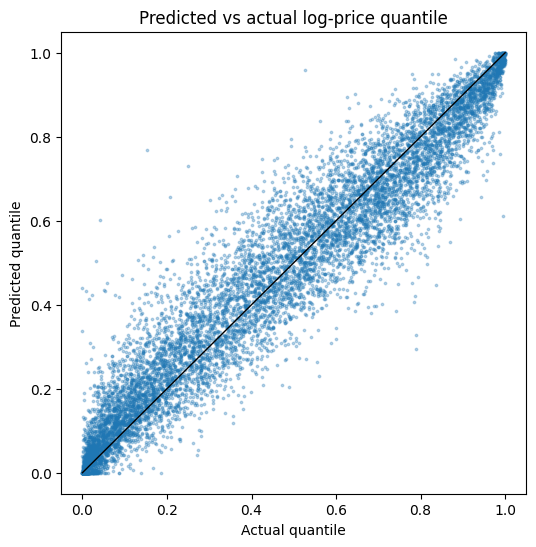

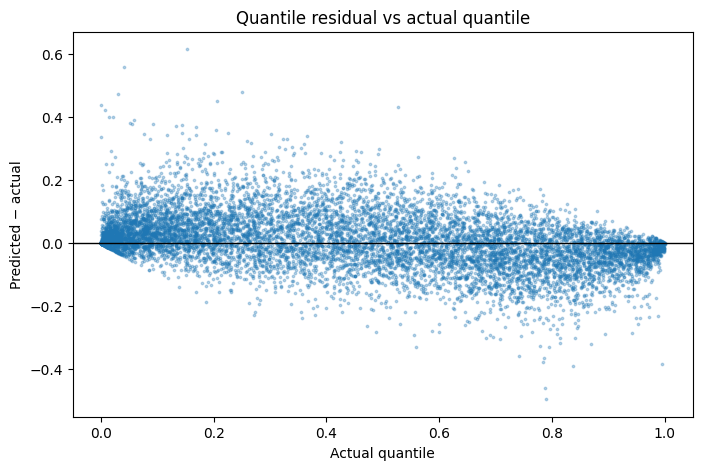

In [12]:
import matplotlib.pyplot as plt

residual = pred_q - actual_q

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(actual_q, pred_q, s=3, alpha=0.3)
ax.plot([0, 1], [0, 1], color="black", linewidth=1)
ax.set(xlabel="Actual quantile", ylabel="Predicted quantile",
       title="Predicted vs actual log-price quantile")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(actual_q, residual, s=3, alpha=0.3)
ax.axhline(0, color="black", linewidth=1)
ax.set(xlabel="Actual quantile", ylabel="Predicted − actual",
       title="Quantile residual vs actual quantile")
plt.show()


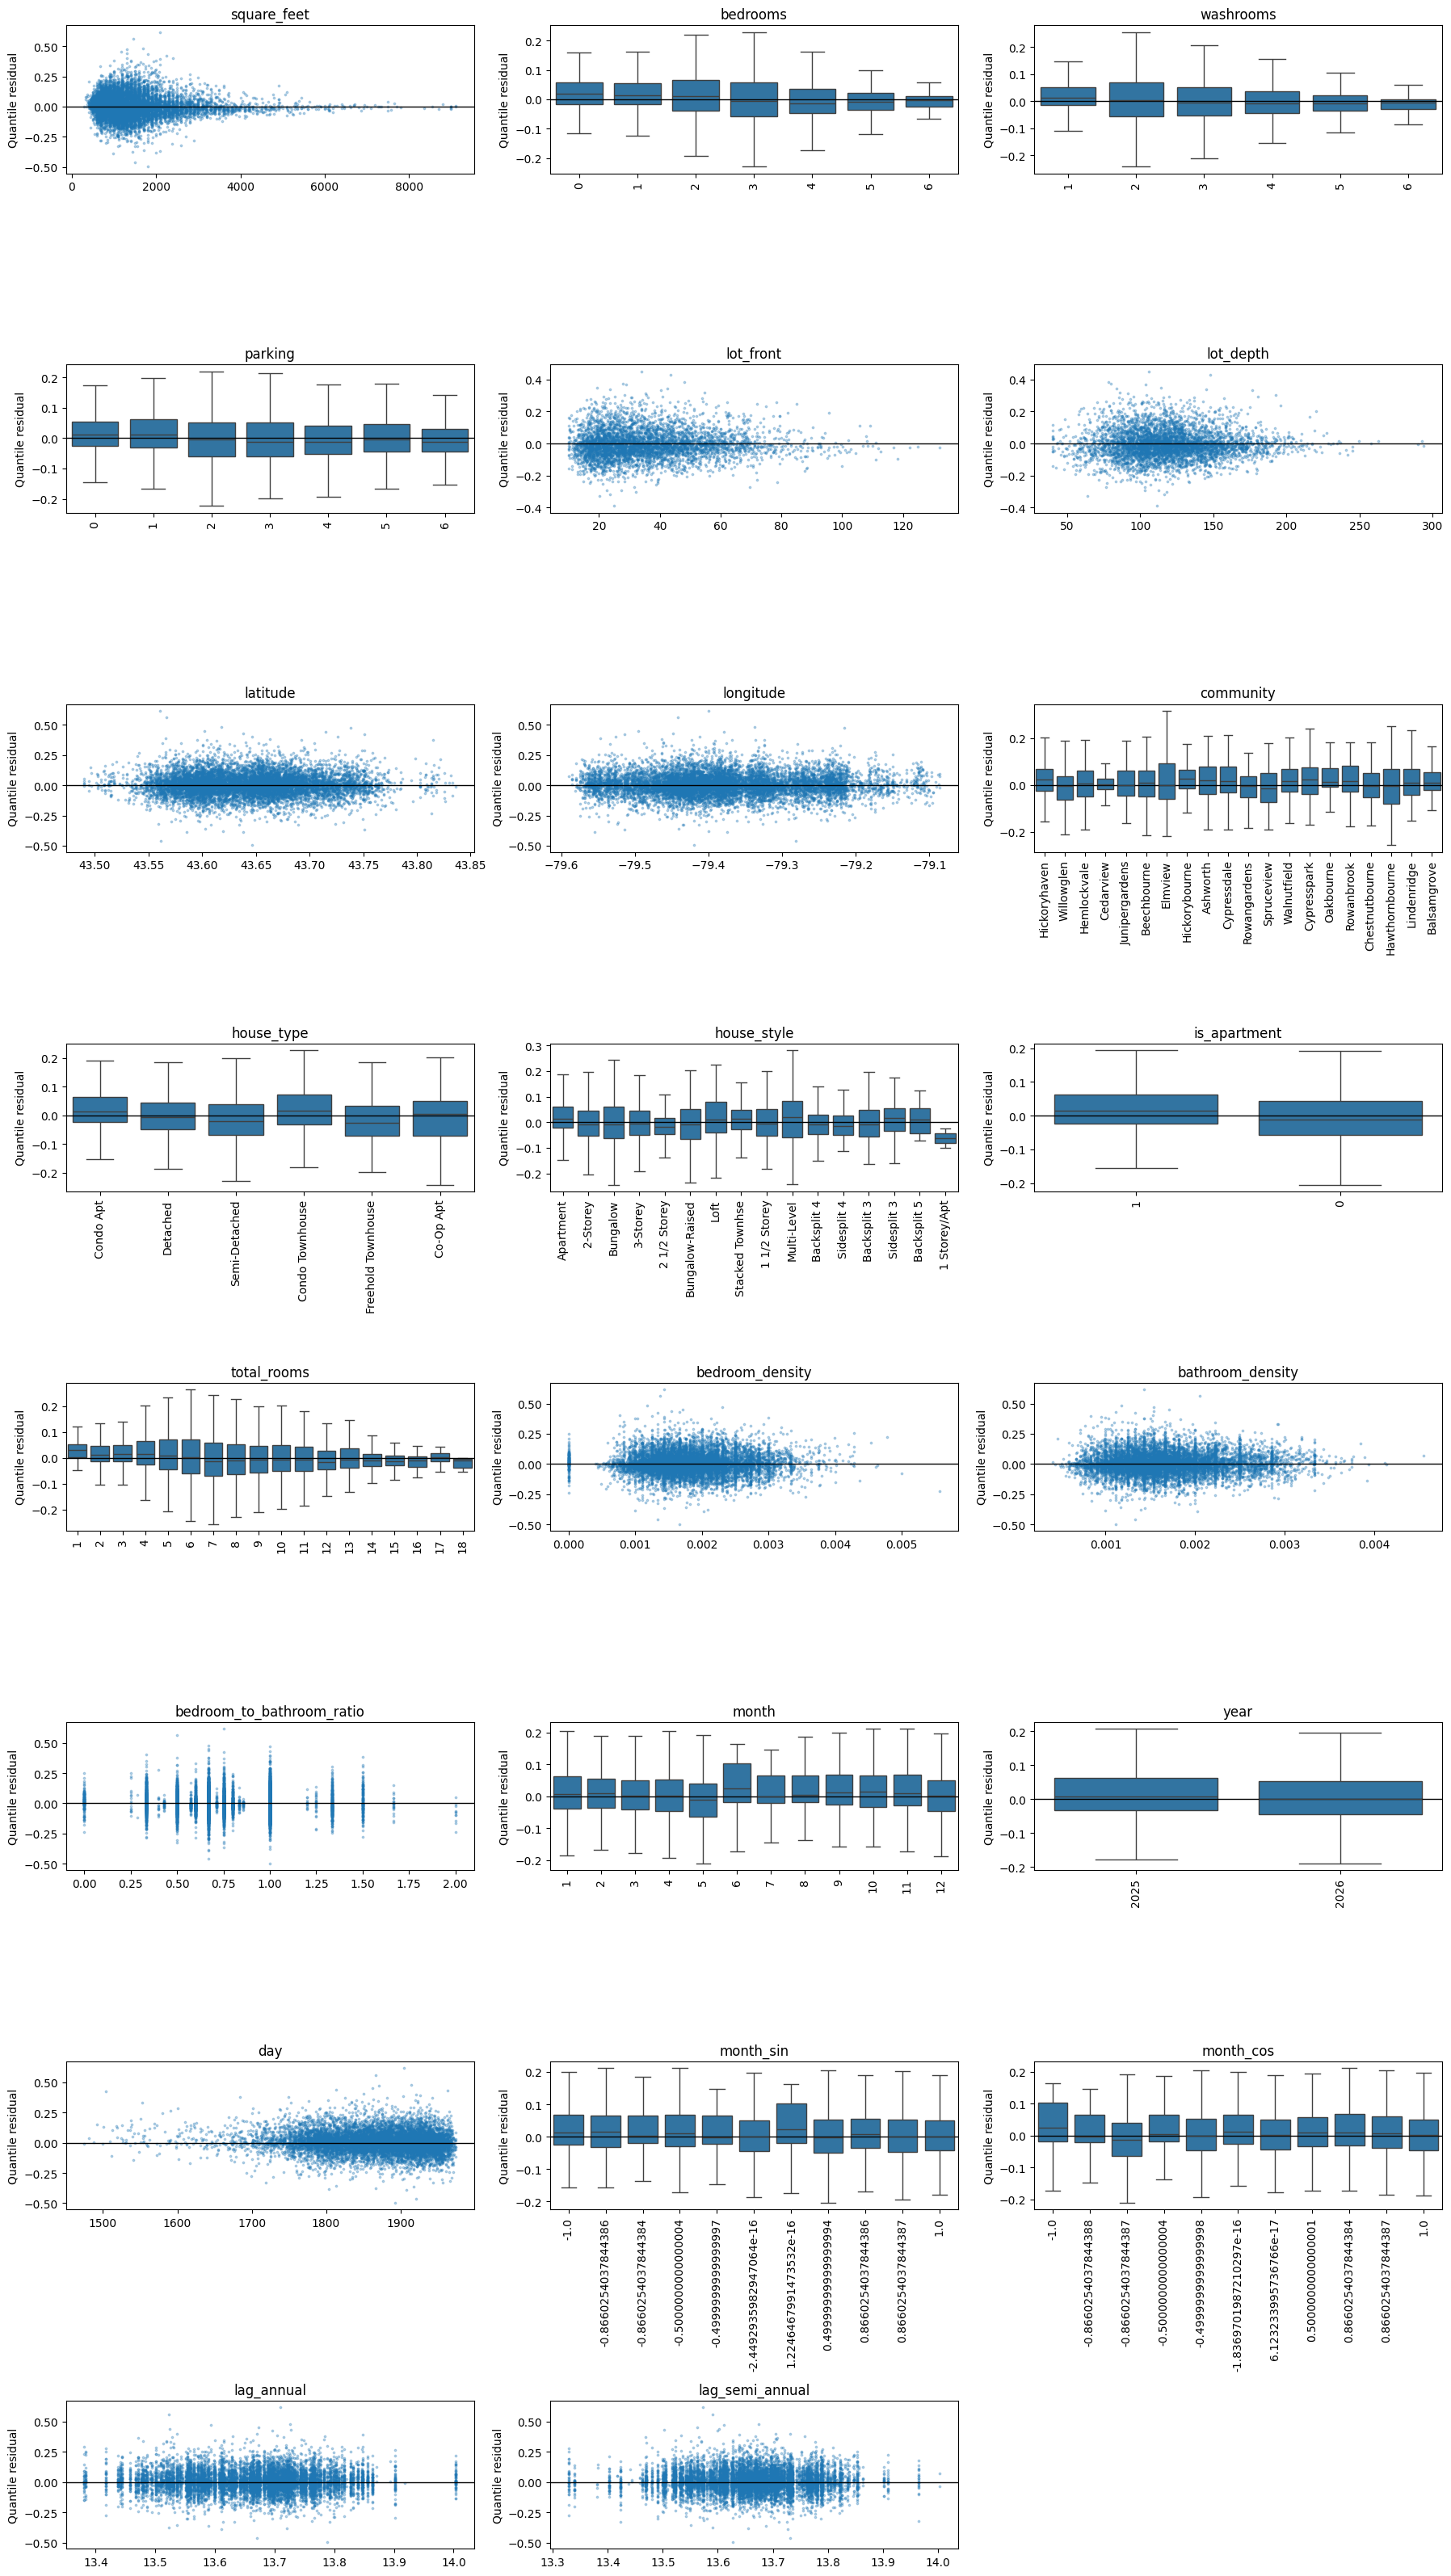

In [13]:
import seaborn as sns

def plot_quantile_residuals_by_feature(X, actual, predicted, max_categories=20, n_cols=3):
    """One panel per column of X. Residual is predicted quantile minus actual quantile."""
    residual = np.asarray(predicted) - np.asarray(actual)
    n_rows = int(np.ceil(len(X.columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)

    for ax, column in zip(axes.flat, X.columns):
        values = X[column].to_numpy()
        is_numeric = pd.api.types.is_numeric_dtype(X[column])
        if is_numeric and X[column].nunique() > max_categories:
            ax.scatter(values, residual, s=3, alpha=0.3)
        else:
            order = X[column].value_counts().index[:max_categories].tolist()
            if is_numeric:
                order = sorted(order)
            sns.boxplot(x=values, y=residual, order=order, showfliers=False, ax=ax)
            ax.tick_params(axis="x", rotation=90)
        ax.axhline(0, color="black", linewidth=1)
        ax.set(title=column, xlabel="", ylabel="Quantile residual")

    for ax in axes.flat[len(X.columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

plot_quantile_residuals_by_feature(X_val, actual_q, pred_q)


In [ ]:
# Interior edges of the predicted-quantile bins, in increasing order. [0.10, 0.90] gives
# 0-10%, 10-90%, 90-100%. A prediction exactly on an edge goes to the upper bin.
BIN_EDGES = [0.10, 0.90]
BIN_NAMES = [f"{lo:.0%}-{hi:.0%}" for lo, hi in zip([0, *BIN_EDGES], [*BIN_EDGES, 1])]


def assign_bin(quantiles):
    return np.asarray(BIN_NAMES, dtype=object)[np.searchsorted(BIN_EDGES, quantiles, side="right")]


def percent_errors(y_log, pred_log):
    return 100 * np.abs(np.exp(pred_log) / np.exp(y_log) - 1)


def fit_bin_models(X_fit, y_fit, bin_fit, params, n_rounds, X_es=None, y_es=None, bin_es=None):
    """Fit one log-price model per bin on that bin's rows only.
    n_rounds is an int for every bin or a dict of bin -> rounds. With early-stopping rows,
    each bin stops on its own early-stopping rows and n_rounds is the cap.
    Bins with no fitting rows get no model. Returns (models, rounds used per bin)."""
    models, rounds = {}, {}
    for name in BIN_NAMES:
        fit_pos = np.flatnonzero(bin_fit == name)
        if len(fit_pos) == 0:
            continue
        es_pos = np.flatnonzero(bin_es == name) if bin_es is not None else []
        model = XGBRegressor(
            **params,
            device=DEVICE,
            n_estimators=n_rounds[name] if isinstance(n_rounds, dict) else n_rounds,
            early_stopping_rounds=EARLY_STOPPING_ROUNDS if len(es_pos) else None,
            random_state=SEED,
        )
        eval_set = [(X_es.iloc[es_pos], y_es[es_pos])] if len(es_pos) else None
        model.fit(X_fit.iloc[fit_pos], y_fit[fit_pos], eval_set=eval_set, verbose=False)
        models[name] = model
        if len(es_pos):
            rounds[name] = model.best_iteration + 1
    return models, rounds


def predict_bins(models, X, bins, fallback):
    """Route each row to its bin's model. Rows in a bin without a model use models[fallback]."""
    pred_log = np.empty(len(X))
    for name in BIN_NAMES:
        pos = np.flatnonzero(bins == name)
        if len(pos):
            pred_log[pos] = models.get(name, models[fallback]).predict(X.iloc[pos])
    return pred_log


def largest_bin(bins):
    return pd.Series(bins).value_counts().idxmax()


def bin_report(y_log, pred_log, bins):
    """Overall and per-bin (MdAPE, MAPE). A bin with no rows is left out."""
    error = percent_errors(y_log, pred_log)
    report = {"all": (np.median(error), error.mean(), len(error))}
    for name in BIN_NAMES:
        mask = bins == name
        if mask.any():
            report[name] = (np.median(error[mask]), error[mask].mean(), mask.sum())
    return report


In [ ]:
def build_pipeline_folds(homes, quantile_params, K=5):
    """Fit the quantile model inside each time-series fold, then bin its predictions.

    Fitting-row bins are that model's predictions on rows it trained on. Validation rows
    are not used for fitting, early stopping, or the training bins. Price trials reuse
    these folds because the quantile parameters are already chosen.
    """
    folds = []
    for fold, (train_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=K).split(homes), start=1):
        n_fit = int(len(train_idx) * (1 - ES_FRACTION))
        fit_idx, es_idx = train_idx[:n_fit], train_idx[n_fit:]
        train_homes = homes.iloc[train_idx]
        fit_prices = homes.iloc[fit_idx]["sold_price"]
        X_tr = make_features(train_homes)
        X_va = align_categories(
            X_tr, make_features(homes.iloc[val_idx], history=train_homes)
        )
        X_fit, X_es = X_tr.iloc[:n_fit], X_tr.iloc[n_fit:]
        y_fit = log_sold_price_quantile(fit_prices, fit_prices)
        y_es = log_sold_price_quantile(homes.iloc[es_idx]["sold_price"], fit_prices)

        quantile_model = XGBRegressor(
            **quantile_params,
            objective="reg:quantileerror",
            quantile_alpha=QUANTILE_ALPHA,
            enable_categorical=True,
            device=DEVICE,
            n_estimators=N_ESTIMATORS,
            early_stopping_rounds=EARLY_STOPPING_ROUNDS,
            random_state=SEED,
        )
        quantile_model.fit(X_fit, y_fit, eval_set=[(X_es, y_es)], verbose=False)
        bin_fit = assign_bin(np.clip(quantile_model.predict(X_fit), 0, 1))
        bin_es = assign_bin(np.clip(quantile_model.predict(X_es), 0, 1))
        bin_va = assign_bin(np.clip(quantile_model.predict(X_va), 0, 1))
        folds.append({
            "X_fit": X_fit,
            "X_es": X_es,
            "X_va": X_va,
            "y_fit": np.log(homes.iloc[fit_idx]["sold_price"].to_numpy()),
            "y_es": np.log(homes.iloc[es_idx]["sold_price"].to_numpy()),
            "y_va": np.log(homes.iloc[val_idx]["sold_price"].to_numpy()),
            "bin_fit": bin_fit,
            "bin_es": bin_es,
            "bin_va": bin_va,
        })
        counts = "  ".join(
            f"{name} fit {(bin_fit == name).sum():,} / val {(bin_va == name).sum():,}"
            for name in BIN_NAMES
        )
        print(f"fold {fold}: quantile rounds {quantile_model.best_iteration + 1}  {counts}", flush=True)
    return folds


pipeline_folds = build_pipeline_folds(train, study.best_params, K=K_FOLDS)


In [ ]:
def cross_val_prices(folds, params, debug=False):
    """Fit one log-price model per bin on each cached fold and score the routed predictions.
    Returns (mean MdAPE, mean MAPE, mean boosting rounds per bin)."""
    reports = []
    rounds = {name: [] for name in BIN_NAMES}

    for fold_number, fold in enumerate(folds, start=1):
        models, fold_rounds = fit_bin_models(
            fold["X_fit"], fold["y_fit"], fold["bin_fit"], params, N_ESTIMATORS,
            fold["X_es"], fold["y_es"], fold["bin_es"],
        )
        for name, n in fold_rounds.items():
            rounds[name].append(n)
        pred_log = predict_bins(models, fold["X_va"], fold["bin_va"], largest_bin(fold["bin_fit"]))
        reports.append(bin_report(fold["y_va"], pred_log, fold["bin_va"]))

        if debug:
            line = "  ".join(
                f"{name} {mdape:.2f}%/{mape:.2f}% (n {n:,})" for name, (mdape, mape, n) in reports[-1].items()
            )
            print(f"fold {fold_number} MdAPE/MAPE: {line}", flush=True)

    summary = {
        name: (np.mean([r[name][0] for r in reports if name in r]),
               np.mean([r[name][1] for r in reports if name in r]))
        for name in ["all", *BIN_NAMES] if any(name in r for r in reports)
    }
    print("mean MdAPE/MAPE: " + "  ".join(
        f"{name} {mdape:.2f}%/{mape:.2f}%" for name, (mdape, mape) in summary.items()
    ), flush=True)

    # A bin that never had early-stopping rows uses the highest round count of the other bins.
    mean_rounds = {name: int(np.mean(values)) for name, values in rounds.items() if values}
    default_rounds = max(mean_rounds.values()) if mean_rounds else N_ESTIMATORS
    mean_rounds = {name: mean_rounds.get(name, default_rounds) for name in BIN_NAMES}
    return summary["all"][0], summary["all"][1], mean_rounds


def price_objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
        "max_depth": trial.suggest_int("max_depth", 3, 13),
        "subsample": trial.suggest_float("subsample", 0.1, 1.0, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0, step=0.1),
        "max_bin": trial.suggest_int("max_bin", 256, 2048),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 0.1, step=0.01),
        "lambda": trial.suggest_float("lambda", 1e-3, 10.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-3, 10.0, log=True),
        "max_delta_step": trial.suggest_int("max_delta_step", 1, 10),
        "enable_categorical": True,
    }
    score, mape, n_rounds = cross_val_prices(pipeline_folds, params, debug=DEBUG)
    trial.set_user_attr("mape", mape)
    trial.set_user_attr("n_rounds", n_rounds)
    return score


In [ ]:
price_study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    study_name="quantile_bin_log_price",
)
price_study.optimize(price_objective, n_trials=N_TRIALS)

print("best CV MdAPE:", round(price_study.best_value, 2))
print("best CV MAPE:", round(price_study.best_trial.user_attrs["mape"], 2))
print("best params:", price_study.best_params)
print("boosting rounds:", price_study.best_trial.user_attrs["n_rounds"])


In [ ]:
price_importance = get_param_importances(price_study)

for param, score in price_importance.items():
    print(f"{param}: {score:.4f}")


In [ ]:
# Refit on every training sale. Bins come from the quantile model fit above.
# Each bin's round count is the mean from cross validation, so the holdout is only scored.
train_bins = assign_bin(np.clip(model.predict(X_train), 0, 1))
val_bins = assign_bin(np.clip(model.predict(X_val), 0, 1))
y_train_log = np.log(train["sold_price"].to_numpy())
price_models, _ = fit_bin_models(
    X_train, y_train_log, train_bins,
    {**price_study.best_params, "enable_categorical": True},
    price_study.best_trial.user_attrs["n_rounds"],
)
predicted_log = predict_bins(price_models, X_val, val_bins, largest_bin(train_bins))
predicted_price = np.exp(predicted_log)

for name, (mdape, mape, n) in bin_report(np.log(val["sold_price"].to_numpy()), predicted_log, val_bins).items():
    print(f"{TRACK} {name}: n {n:,}  MdAPE {mdape:.2f}%  MAPE {mape:.2f}%")


In [ ]:
for name, price_model in price_models.items():
    importances = pd.Series(price_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
    print(name)
    display(importances)


In [ ]:
import diagnostics

actual_price = val["sold_price"]

diagnostics.plot_residuals_vs_actual(actual_price, predicted_price)
diagnostics.plot_predicted_vs_actual(actual_price, predicted_price)
diagnostics.plot_residuals_by_feature(X_val, actual_price, predicted_price)
